# Home Task 1 - Improving the TSP Program

**Student:** _Replace with your name_  
**Course:** AI Introduction

## Task

Keep the lecture's simulated-annealing and point-generation settings, but improve the Traveling Salesman Problem solver by replacing the simple random swap with a **2-opt path reversal**.

This notebook compares the original simple-swap neighborhood with the improved 2-opt neighborhood on exactly the same 100 generated cities.

## Improvement

The original candidate generator swaps two city positions. The improved generator chooses two indices `i < j` and reverses `route[i:j+1]`.

For example:

`[1, 2, 3, 4, 5, 6, 7] -> [1, 5, 4, 3, 2, 6, 7]`

This is the 2-opt operation requested in the lecture.

In [1]:
from pathlib import Path
from IPython.display import Image, display
from tsp_homework1 import Config, run_experiment

config = Config(
    n_cities=100,
    initial_temperature=100,
    end_temperature=0,
    iterations=100_000,
    city_seed=42,
    optimizer_seed=43,
    coordinate_limit=10,
    metric="euclidean",
)

summary = run_experiment(config, Path("notebook_results"))
summary

{'config': {'n_cities': 100,
  'initial_temperature': 100,
  'end_temperature': 0,
  'iterations': 100000,
  'city_seed': 42,
  'optimizer_seed': 43,
  'coordinate_limit': 10,
  'metric': 'euclidean'},
 'initial_route_length': 542.7561547587117,
 'baseline': {'algorithm': 'Simple-swap simulated annealing',
  'route_length': 139.08199443035454,
  'accepted_moves': 315,
  'improving_moves': 308,
  'route': [25,
   43,
   1,
   46,
   88,
   15,
   87,
   35,
   58,
   6,
   52,
   75,
   38,
   85,
   10,
   24,
   94,
   51,
   95,
   16,
   69,
   0,
   27,
   98,
   60,
   63,
   78,
   37,
   81,
   9,
   30,
   11,
   21,
   5,
   34,
   12,
   4,
   93,
   47,
   31,
   44,
   59,
   40,
   96,
   91,
   26,
   57,
   68,
   97,
   42,
   83,
   55,
   90,
   61,
   18,
   41,
   39,
   65,
   86,
   71,
   48,
   80,
   22,
   92,
   66,
   29,
   74,
   28,
   49,
   2,
   7,
   54,
   72,
   14,
   89,
   77,
   70,
   67,
   19,
   73,
   33,
   82,
   3,
   36,
   64,
   20,
 

In [2]:
print(f"Initial route length: {summary['initial_route_length']:.6f}")
print(f"Simple-swap SA:      {summary['baseline']['route_length']:.6f}")
print(f"2-opt SA:            {summary['improved']['route_length']:.6f}")
print(
    "Improvement over baseline: "
    f"{summary['improvement']['percent_vs_baseline']:.2f}%"
)

Initial route length: 542.756155
Simple-swap SA:      139.081994
2-opt SA:            80.533170
Improvement over baseline: 42.10%


## Initial route

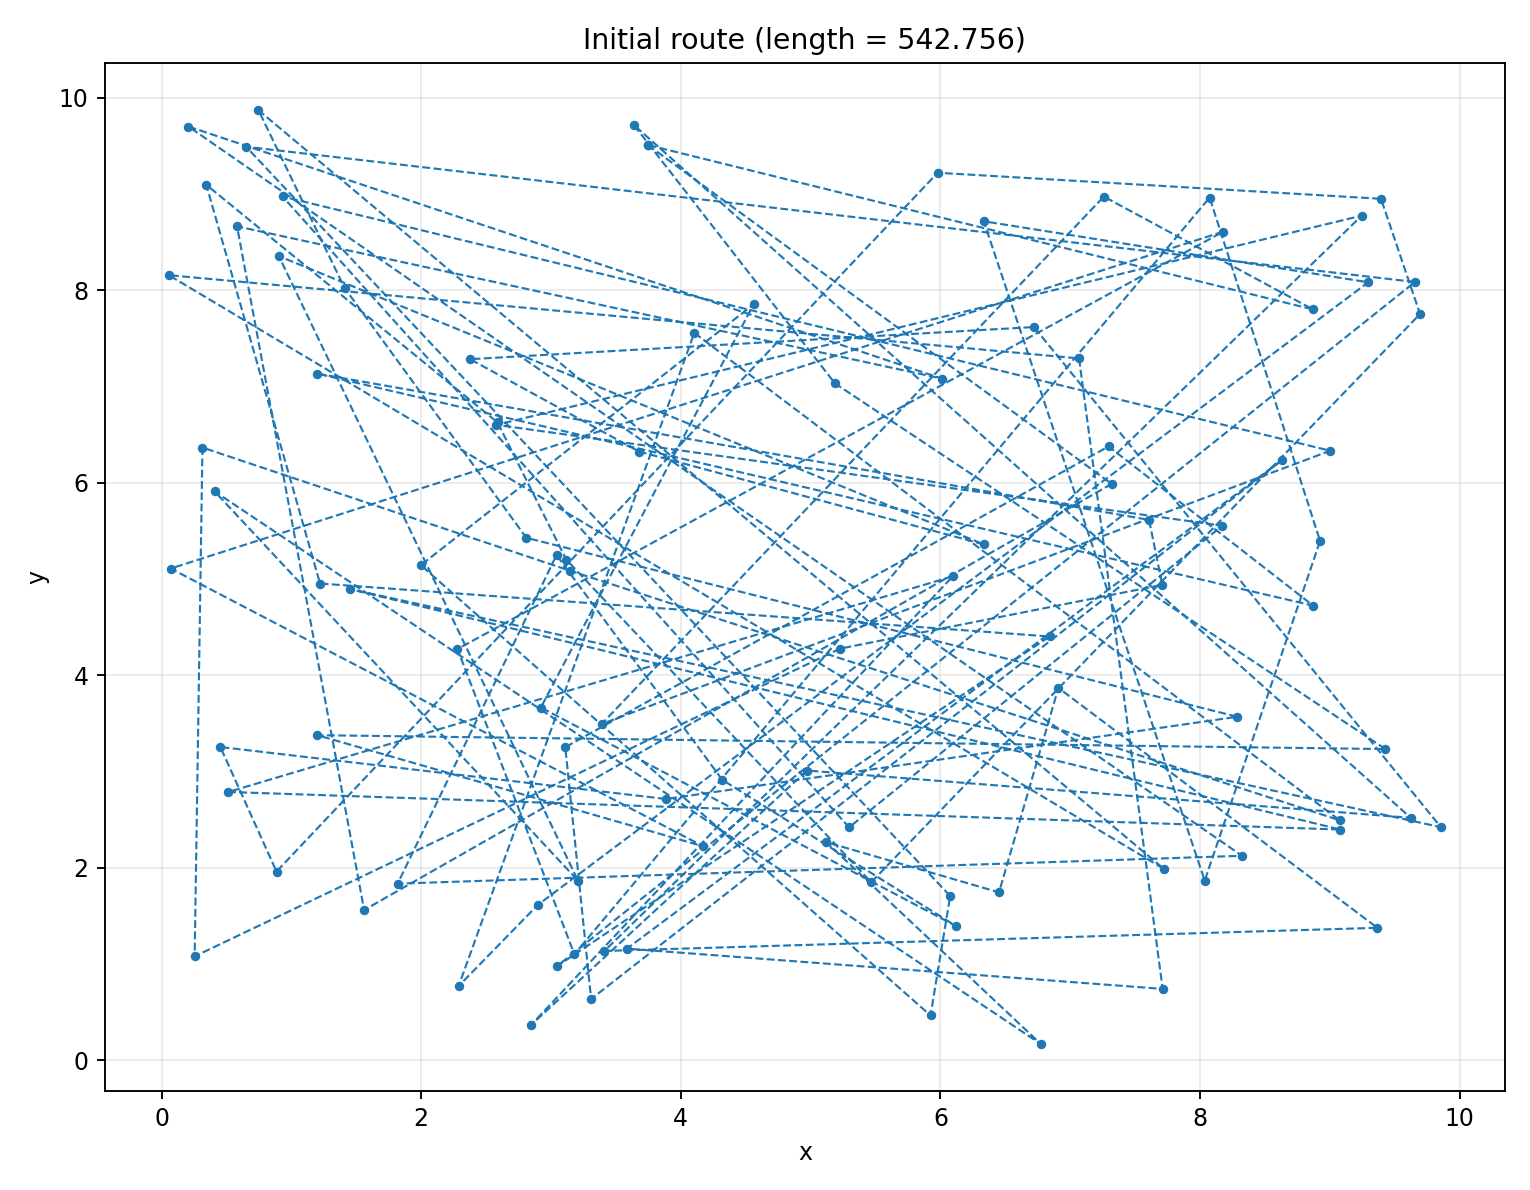

In [3]:
display(Image(filename="notebook_results/initial_route.png"))

## Baseline: simple-swap simulated annealing

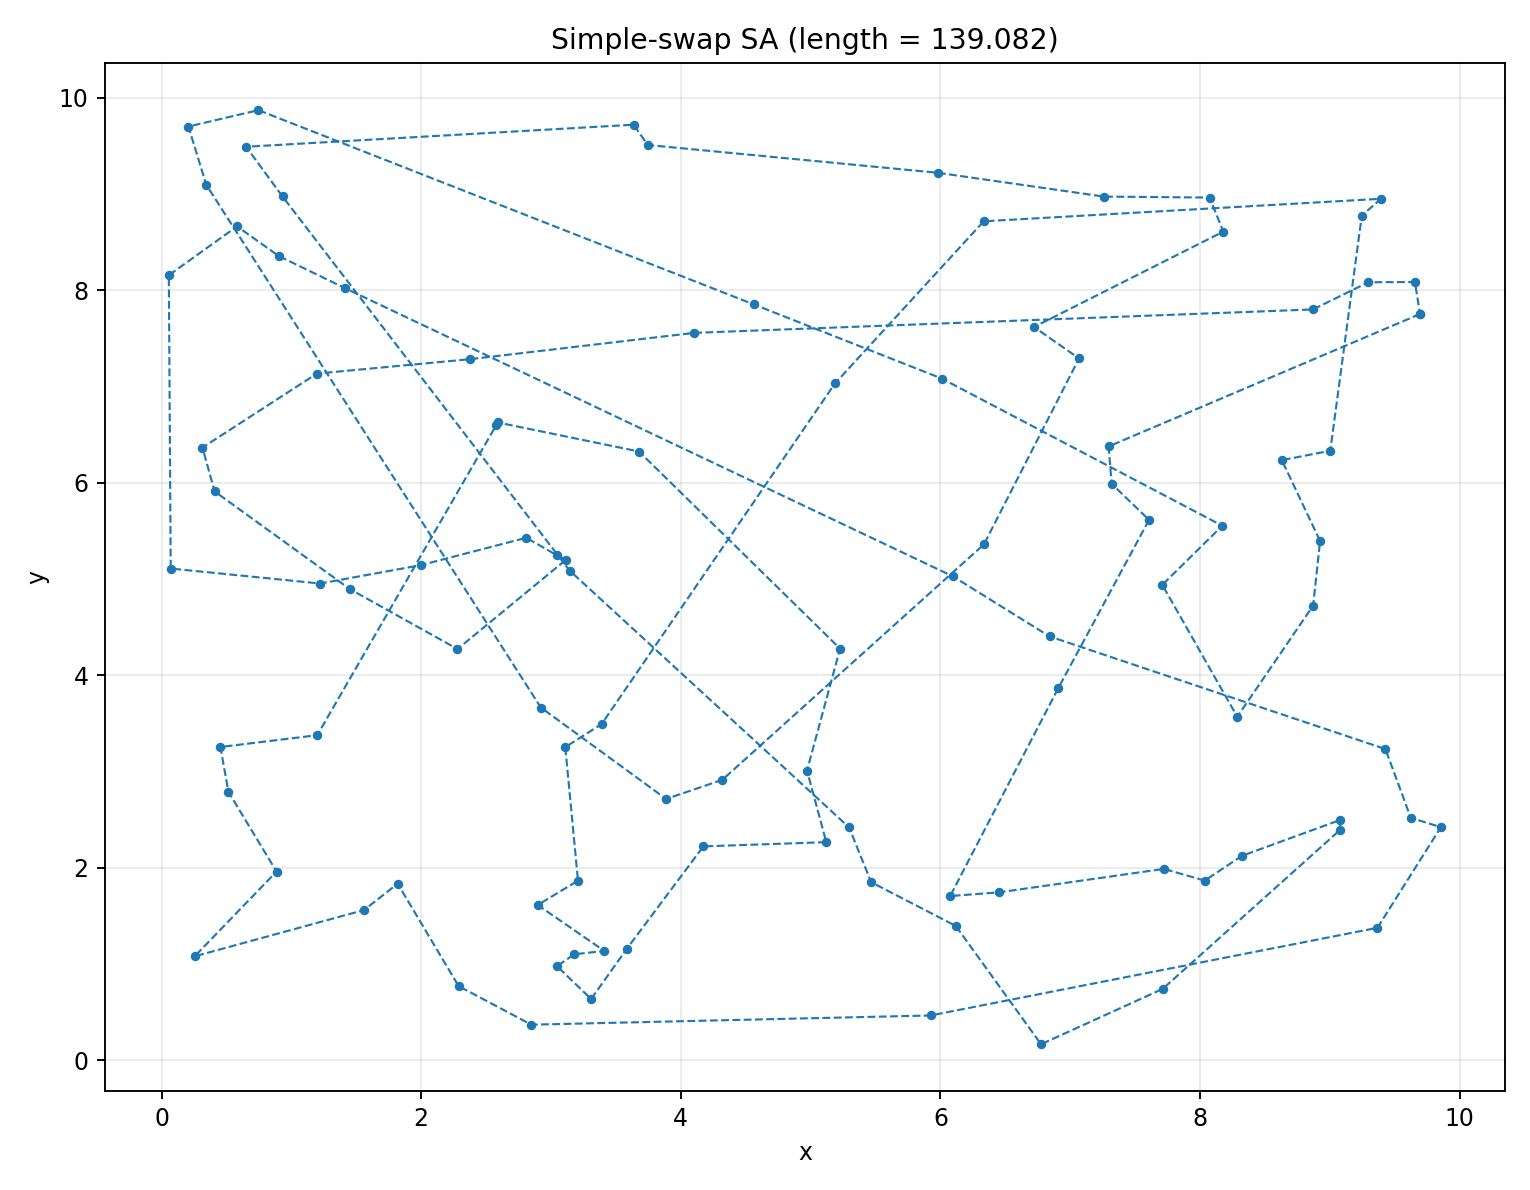

In [4]:
display(Image(filename="notebook_results/baseline_swap_route.png"))

## Improved result: 2-opt simulated annealing

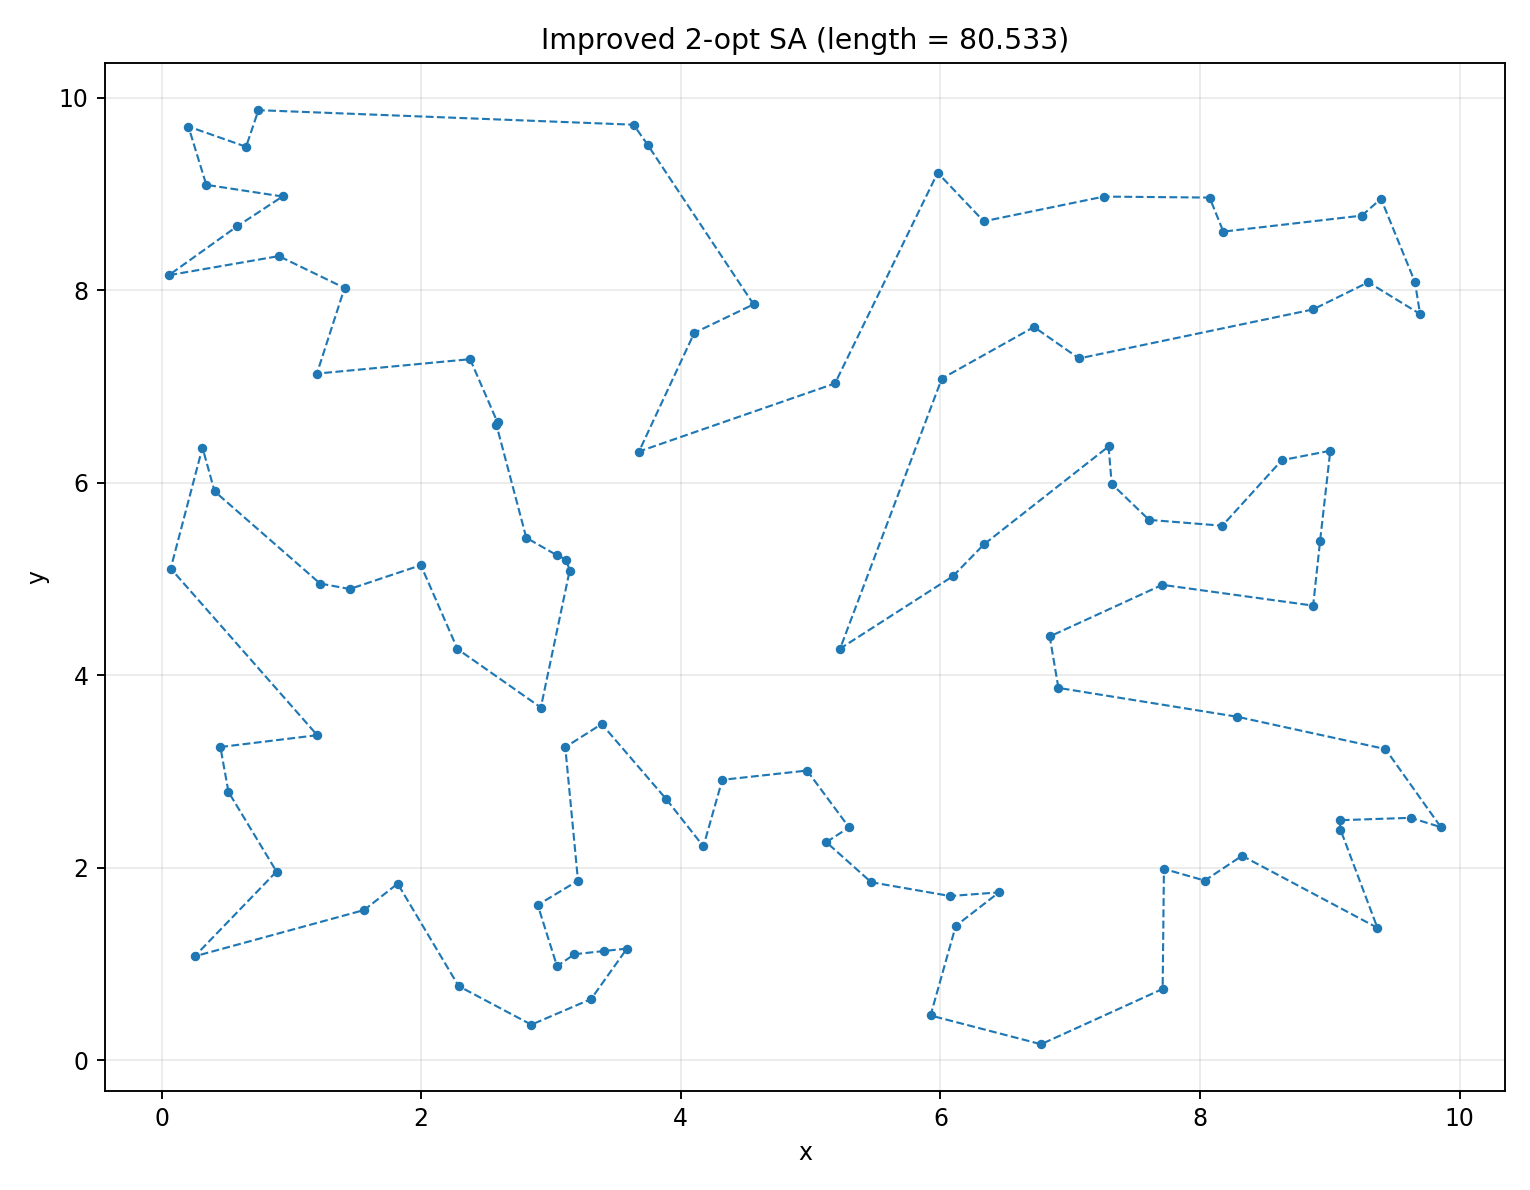

In [5]:
display(Image(filename="notebook_results/improved_2opt_route.png"))

## Numerical comparison

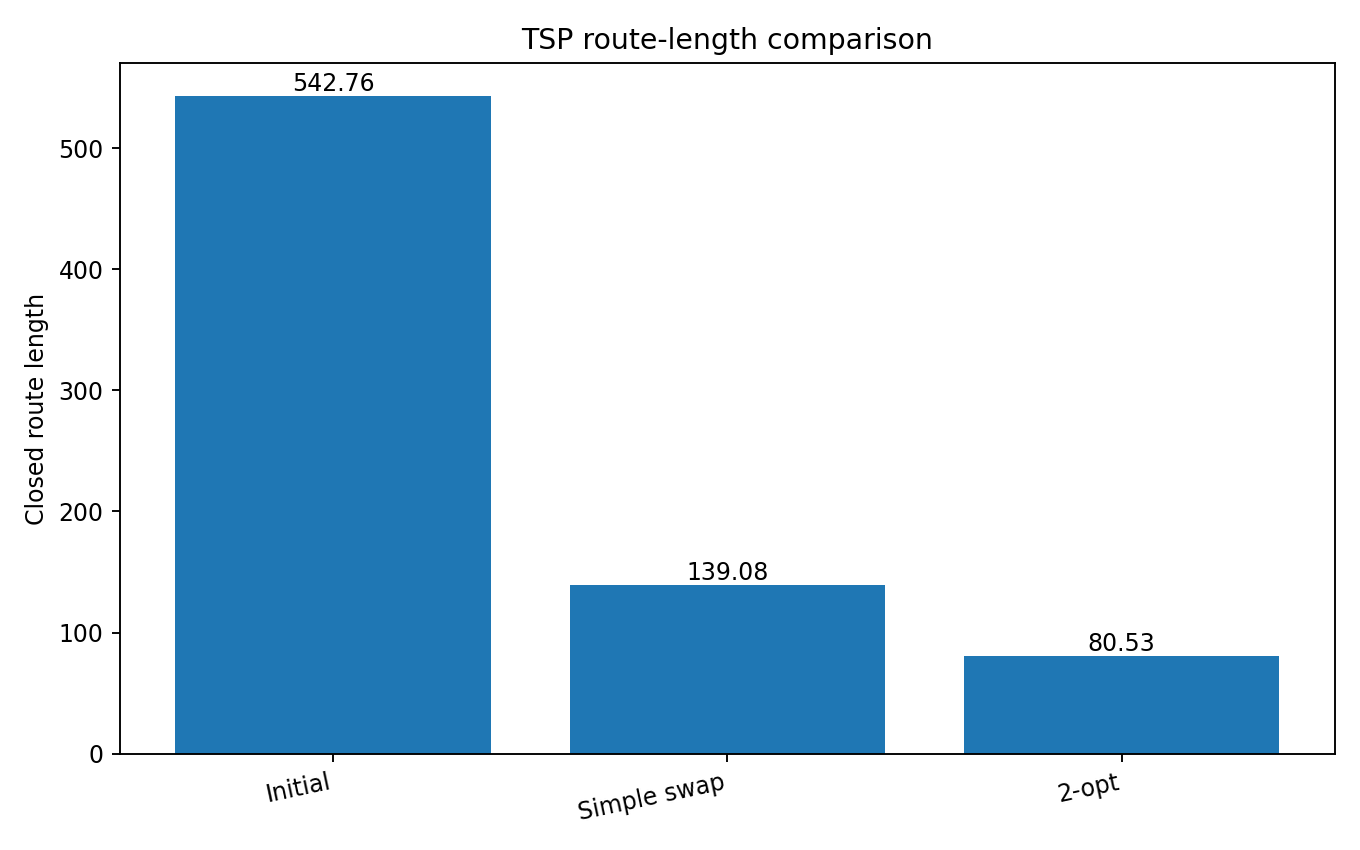

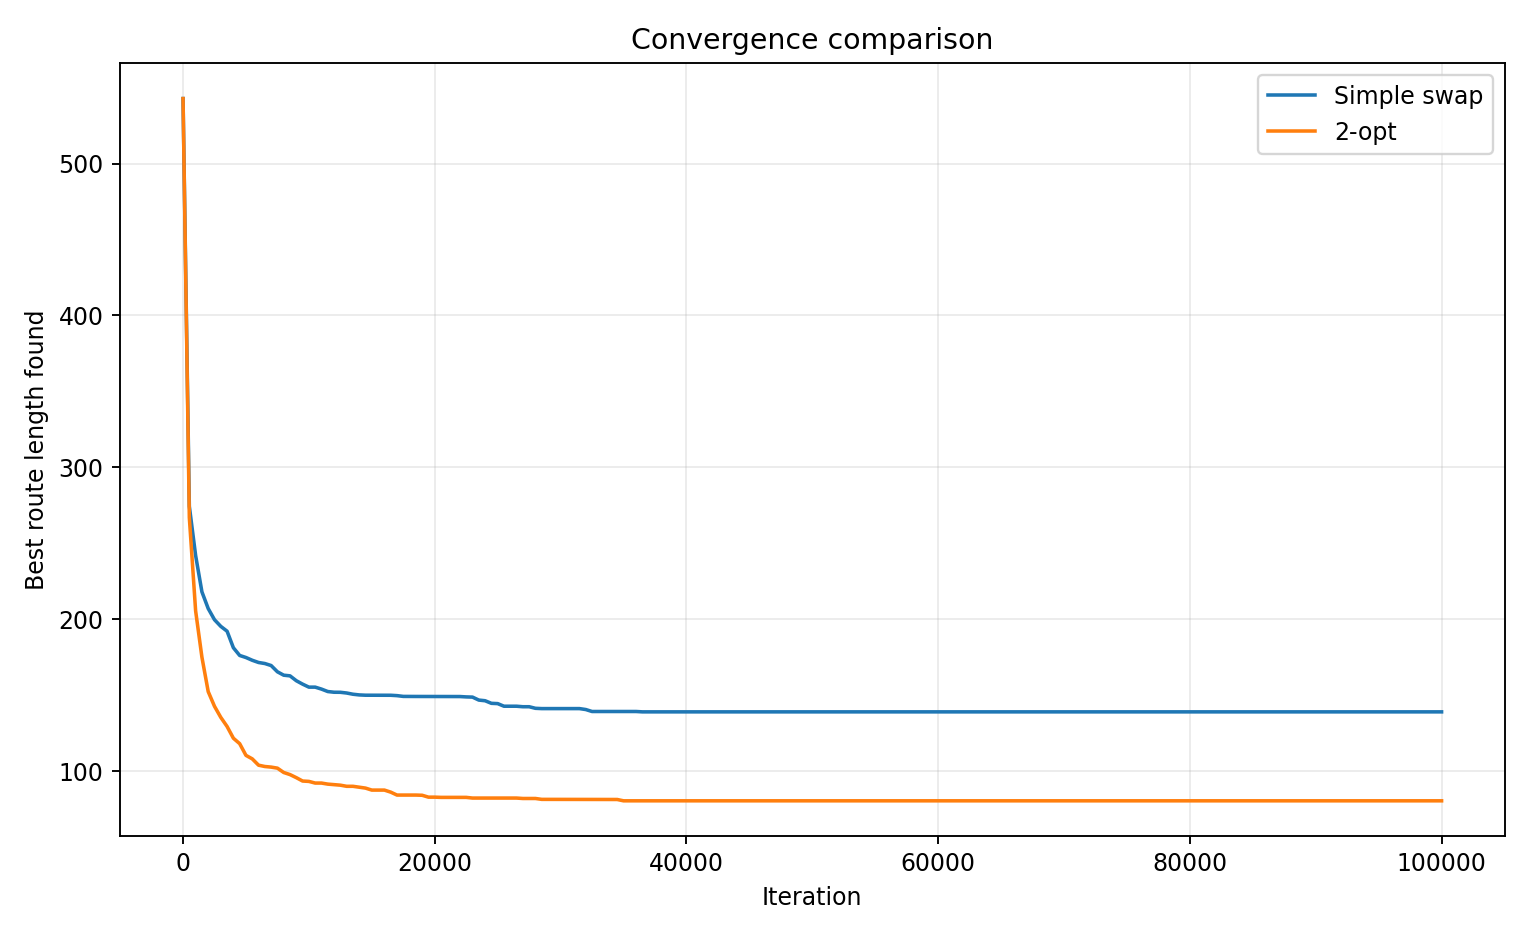

In [6]:
display(Image(filename="notebook_results/route_length_comparison.png"))
display(Image(filename="notebook_results/convergence_comparison.png"))

## Conclusion

The 2-opt neighborhood produces a substantially shorter route than the original simple-swap neighborhood for the same generated cities, temperature settings, iteration budget, and reproducible random seeds.

The improvement comes from reversing a continuous route segment, which directly replaces two long boundary edges and commonly removes crossings. The implementation also stores the best route found during the complete simulated-annealing run.